# Comparative Analysis of Cytochrome c Protein Sequences in Humans and Non-Human Primates

**Computing for Bioinformatics — Group Project, Strathmore University (2026)**

**Group members:** Nicole Njeri · Abraham Seleshi · Fatma Marsa · Alysa Macharia · Scott Katana

**Data source:** UniProtKB (https://www.uniprot.org), downloaded programmatically through the UniProt REST API.

**How to run:** open in Google Colab, choose *Runtime → Run all*, and allow access to Google Drive when asked. The first run downloads the data from UniProt into the group's Drive folder. Later runs reuse those saved files, so results stay reproducible even if UniProt records are updated.

## Stage 1 — Research question and objectives

**Research question:** How conserved is the cytochrome c protein sequence across humans and selected non-human primates, and do sequence similarities reflect their evolutionary relationships?

**Objectives (approved by the lecturer)**
1. Retrieve and document cytochrome c protein sequences for the selected primate species from UniProtKB.
2. Check sequence completeness and length, remove duplicate or unsuitable records, and perform a multiple sequence alignment.
3. Measure sequence identity and locate conserved and variable amino acid positions, presenting the findings with clear plots or tables.
4. Use sequence-similarity results to construct a phylogenetic and clustering comparison, and discuss the biological interpretation and limitations.

**Hypotheses**
- **H1 (conservation):** Cytochrome c from human, chimpanzee, gorilla and orangutan is identical or nearly identical (≥ 99 % identity), because the protein is under strong functional constraint.
- **H2 (evolutionary signal):** Across a wider set of vertebrates, sequence distance increases with taxonomic distance, and a sequence-based tree groups species in line with accepted taxonomy.
- **H3 (prediction):** A model using cytochrome c sequence alone can assign sequences to their taxonomic group better than a majority-class baseline.

**Dataset design.** Because cytochrome c is extremely conserved among great apes, four sequences alone cannot support exploratory analysis, tree building or machine learning. The data is therefore organised in three tiers:

| Tier | Contents | Purpose |
|---|---|---|
| 1 — core | Human, chimpanzee, gorilla, orangutan | Directly answers the research question |
| 2 — wider primates | Other primates with a CYCS record | Shows where differences first appear within primates |
| 3 — wider vertebrates | Reviewed cytochrome c records from other vertebrates | Provides the variation needed for EDA, the tree, the statistical test and ML |

In [1]:
# Colab setup: MAFFT (multiple sequence alignment) and two packages not preinstalled in Colab
!apt-get -qq install -y mafft > /dev/null 2>&1
!pip -q install biopython logomaker

**Data storage.** The notebook works inside the group's Google Drive folder *My Drive → Bioinformatics project → Bioinformatics project data*. Downloaded UniProt files go into `data/` and figures and tables into `results/` inside that folder, so they are kept permanently and shared by everyone in the group. Once the UniProt files are there, later runs load them instead of downloading again.

In [2]:
# Connect to the group's Google Drive folder; all data/ and results/ files are saved there
import os
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Bioinformatics project/Bioinformatics project data"
if os.path.isdir(PROJECT_DIR):
    os.chdir(PROJECT_DIR)
    print("Working folder:", os.getcwd())
    print("Already in folder:", sorted(os.listdir()) or "nothing yet")
    if os.path.isdir("data"):
        print("Saved UniProt files:", sorted(f for f in os.listdir("data") if f.startswith("raw_")) or "none yet")
else:
    print("Could not find:", PROJECT_DIR)
    print("If the folder was shared with you: open Google Drive -> 'Shared with me', right-click "
          "'Bioinformatics project' -> Organise -> Add shortcut -> My Drive, then run this cell again.")
    print("For now, files will be saved in temporary Colab storage and lost when the session ends.")

Mounted at /content/drive
Working folder: /content/drive/MyDrive/Bioinformatics project/Bioinformatics project data
Already in folder: ['data', 'results']
Saved UniProt files: ['raw_tier1_core.tsv', 'raw_tier2_primates.tsv', 'raw_tier3_vertebrates.tsv']


In [3]:
import io, os, re, json, shutil, subprocess, datetime, warnings
from collections import Counter

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, mannwhitneyu

from Bio import AlignIO, Phylo
from Bio.Align import PairwiseAligner, substitution_matrices
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
import logomaker

from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_validate,
                                     cross_val_predict, permutation_test_score)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)

SUMMARY = {}   # key results collected for the conclusions
print("MAFFT available:", shutil.which("mafft") is not None)

MAFFT available: True


## Stage 2 — Data acquisition

All data comes from **UniProtKB** through its REST API, so the download is part of the code rather than a manual step. Three queries are run:

| Query | UniProt search | Why |
|---|---|---|
| `tier1_core` | The four agreed accessions: P99999 (human), P99998 (chimpanzee), Q6WUX8 (gorilla), Q5RFH4 (orangutan) | The species named in the research question |
| `tier2_primates` | Gene name exactly CYCS, order Primates (taxon 9443), not fragments | Additional primates, reviewed or unreviewed |
| `tier3_vertebrates` | Protein name "cytochrome c", reviewed (Swiss-Prot), Vertebrata (taxon 7742), not fragments, length 95–120 | Wider comparison set; deliberately broad so that QC has to remove look-alike proteins |

In [4]:
UNIPROT_STREAM = "https://rest.uniprot.org/uniprotkb/stream"
FIELDS  = ["accession", "id", "reviewed", "protein_name", "gene_names", "organism_name",
           "organism_id", "length", "lineage", "sequence"]
COLUMNS = ["accession", "entry_name", "reviewed", "protein_name", "gene_names", "organism",
           "taxon_id", "length", "lineage", "sequence"]

CORE = {"P99999": "Human", "P99998": "Chimpanzee", "Q6WUX8": "Gorilla", "Q5RFH4": "Sumatran orangutan"}
HUMAN_ACC = "P99999"

QUERIES = {
    "tier1_core": " OR ".join(f"accession:{a}" for a in CORE),
    "tier2_primates": "(gene_exact:CYCS) AND (taxonomy_id:9443) AND (fragment:false)",
    "tier3_vertebrates": '(protein_name:"cytochrome c") AND (reviewed:true) AND (taxonomy_id:7742) '
                         'AND (fragment:false) AND (length:[95 TO 120])',
}
LOG_PATH = "data/retrieval_log.json"
retrieval_log = json.load(open(LOG_PATH)) if os.path.exists(LOG_PATH) else {}

import time
UNIPROT_SEARCH = "https://rest.uniprot.org/uniprotkb/search"

def polite_get(url, params=None, tries=6):
    # GET with automatic waiting and retrying when UniProt is busy (429) or has a server error (5xx)
    for attempt in range(tries):
        r = requests.get(url, params=params, timeout=180)
        if r.status_code == 429 or r.status_code >= 500:
            wait = int(r.headers.get("Retry-After", 0) or 0) or min(120, 10 * 2 ** attempt)
            print(f"  UniProt busy (HTTP {r.status_code}); waiting {wait}s then retrying ({attempt + 1}/{tries})")
            time.sleep(wait)
            continue
        if r.status_code != 200:
            print("UniProt returned an error:", r.status_code, r.text[:500])
        r.raise_for_status()
        return r
    raise RuntimeError("UniProt is still busy after several retries - wait a few minutes and run this cell again.")

def download_query(query):
    # Try the one-shot stream endpoint first; if it keeps failing, page through the search endpoint instead
    params = {"query": query, "format": "tsv", "fields": ",".join(FIELDS)}
    try:
        r = polite_get(UNIPROT_STREAM, params)
        return r.text, r.url
    except Exception as ex:
        print("  Stream endpoint failed, switching to paginated search:", ex)
    r = polite_get(UNIPROT_SEARCH, {**params, "size": 500})
    first_url, pages = r.url, [r.text]
    while "next" in r.links:
        time.sleep(1)
        r = polite_get(r.links["next"]["url"])
        pages.append(r.text.split("\n", 1)[1])   # drop the repeated header line
    return "".join(pages), first_url

def fetch_uniprot(name, query):
    # Download a UniProt query as TSV, or reuse the saved copy from an earlier run
    path = f"data/raw_{name}.tsv"
    if os.path.exists(path):
        text = open(path).read()
        print(f"{name:18s} loaded saved file {path}")
    else:
        text, url = download_query(query)
        open(path, "w").write(text)
        retrieval_log[name] = {"query": query, "url": url,
                               "retrieved_utc": datetime.datetime.utcnow().isoformat(timespec="seconds")}
        json.dump(retrieval_log, open(LOG_PATH, "w"), indent=2)
        print(f"{name:18s} downloaded from UniProt -> {path}")
        time.sleep(2)   # short pause between queries to stay within UniProt's rate limits
    df = pd.read_csv(io.StringIO(text), sep="\t", dtype=str).fillna("")
    df.columns = COLUMNS
    df["source_query"] = name
    return df

frames = [fetch_uniprot(n, q) for n, q in QUERIES.items()]
for f in frames:
    print(f"  {f.source_query.iloc[0] if len(f) else '?':18s} {len(f):5d} records")

raw = pd.concat(frames, ignore_index=True)
raw["length"] = raw["length"].astype(int)
n_before_merge = len(raw)
raw = raw.drop_duplicates("accession", keep="first").reset_index(drop=True)   # same record returned by two queries
print(f"\nCombined: {n_before_merge} rows -> {len(raw)} unique accessions")

missing_core = [a for a in CORE if a not in set(raw.accession)]
print("Core accessions missing from download:", missing_core or "none")

tier1_core         loaded saved file data/raw_tier1_core.tsv
tier2_primates     loaded saved file data/raw_tier2_primates.tsv
tier3_vertebrates  loaded saved file data/raw_tier3_vertebrates.tsv
  tier1_core             4 records
  tier2_primates        68 records
  tier3_vertebrates     94 records

Combined: 166 rows -> 151 unique accessions
Core accessions missing from download: none


In [5]:
# Source log: one row per downloaded record, saved with the project
retrieved = {k: v.get("retrieved_utc", "") for k, v in retrieval_log.items()}
source_log = raw[["accession", "entry_name", "organism", "reviewed", "length", "source_query"]].copy()
source_log["retrieved_utc"] = source_log.source_query.map(retrieved)
source_log["uniprot_url"] = "https://www.uniprot.org/uniprotkb/" + source_log.accession
source_log.to_csv("data/source_log.csv", index=False)

print("Retrieval log:")
print(json.dumps(retrieval_log, indent=2))
display(raw[raw.accession.isin(CORE)][["accession", "entry_name", "organism", "reviewed", "length", "gene_names"]])
display(raw.head())

Retrieval log:
{
  "tier1_core": {
    "query": "accession:P99999 OR accession:P99998 OR accession:Q6WUX8 OR accession:Q5RFH4",
    "url": "https://rest.uniprot.org/uniprotkb/stream?query=accession%3AP99999+OR+accession%3AP99998+OR+accession%3AQ6WUX8+OR+accession%3AQ5RFH4&format=tsv&fields=accession%2Cid%2Creviewed%2Cprotein_name%2Cgene_names%2Corganism_name%2Corganism_id%2Clength%2Clineage%2Csequence",
    "retrieved_utc": "2026-11-09T10:30:15"
  },
  "tier2_primates": {
    "query": "(gene_exact:CYCS) AND (taxonomy_id:9443) AND (fragment:false)",
    "url": "https://rest.uniprot.org/uniprotkb/stream?query=%28gene_exact%3ACYCS%29+AND+%28taxonomy_id%3A9443%29+AND+%28fragment%3Afalse%29&format=tsv&fields=accession%2Cid%2Creviewed%2Cprotein_name%2Cgene_names%2Corganism_name%2Corganism_id%2Clength%2Clineage%2Csequence",
    "retrieved_utc": "2026-11-09T10:30:18"
  },
  "tier3_vertebrates": {
    "query": "(protein_name:\"cytochrome c\") AND (reviewed:true) AND (taxonomy_id:7742) AND (frag

,accession,entry_name,organism,reviewed,length,gene_names
0,P99999,CYC_HUMAN,Homo sapiens (Human),reviewed,105,CYCS CYC
1,P99998,CYC_PANTR,Pan troglodytes (Chimpanzee),reviewed,105,CYCS CYC
2,Q5RFH4,CYC_PONAB,Pongo abelii (Sumatran orangutan) (Pongo pygmaeus abelii),reviewed,105,CYCS CYC
3,Q6WUX8,CYC_GORGO,Gorilla gorilla gorilla (Western lowland gorilla),reviewed,105,CYCS CYC


,accession,entry_name,reviewed,protein_name,gene_names,organism,taxon_id,length,lineage,sequence,source_query
0,P99999,CYC_HUMAN,reviewed,Cytochrome c,CYCS CYC,Homo sapiens (Human),9606,105,"cellular organisms (no rank), Eukaryota (domain), Opisthokonta (cl...",MGDVEKGKKIFIMKCSQCHTVEKGGKHKTGPNLHGLFGRKTGQAPGYSYTAANKNKGIIWGEDTLM...,tier1_core
1,P99998,CYC_PANTR,reviewed,Cytochrome c,CYCS CYC,Pan troglodytes (Chimpanzee),9598,105,"cellular organisms (no rank), Eukaryota (domain), Opisthokonta (cl...",MGDVEKGKKIFIMKCSQCHTVEKGGKHKTGPNLHGLFGRKTGQAPGYSYTAANKNKGIIWGEDTLM...,tier1_core
2,Q5RFH4,CYC_PONAB,reviewed,Cytochrome c,CYCS CYC,Pongo abelii (Sumatran orangutan) (Pongo pygmaeus abelii),9601,105,"cellular organisms (no rank), Eukaryota (domain), Opisthokonta (cl...",MGDVEKGKKIFIMKCSQCHTVEKGGKHKTGPNLHGLFGRKTGQAPGYSYTAANKNKGIIWGEDTLM...,tier1_core
3,Q6WUX8,CYC_GORGO,reviewed,Cytochrome c,CYCS CYC,Gorilla gorilla gorilla (Western lowland gorilla),9595,105,"cellular organisms (no rank), Eukaryota (domain), Opisthokonta (cl...",MGDVEKGKKIFIMKCSQCHTVEKGGKHKTGPNLHGLFGRKTGQAPGYSYTAANKNKGIIWGEDTLM...,tier1_core
4,P00002,CYC_MACMU,reviewed,Cytochrome c,CYCS CYC,Macaca mulatta (Rhesus macaque),9544,105,"cellular organisms (no rank), Eukaryota (domain), Opisthokonta (cl...",MGDVEKGKKIFIMKCSQCHTVEKGGKHKTGPNLHGLFGRKTGQAPGYSYTAANKNKGITWGEDTLM...,tier2_primates


**Files and variables**

| File | Contents |
|---|---|
| `data/raw_tier1_core.tsv`, `data/raw_tier2_primates.tsv`, `data/raw_tier3_vertebrates.tsv` | Unedited UniProt downloads, one per query |
| `data/retrieval_log.json` | Exact query, URL and UTC date of each download |
| `data/source_log.csv` | Accession, organism, review status, length and source query for every downloaded record |
| `data/cytc_clean.fasta` | Sequences that passed quality control (Stage 3) |
| `data/cytc_aligned.fasta` | MAFFT multiple sequence alignment (Stage 5) |
| `data/P99999_features.json` | UniProt functional annotation of human cytochrome c (Stage 6) |

| Variable | Meaning |
|---|---|
| `accession` | UniProt accession number, the stable identifier of the record |
| `entry_name` | UniProt entry name (e.g. CYC_HUMAN) |
| `reviewed` | "reviewed" = manually curated Swiss-Prot entry; "unreviewed" = automatically annotated TrEMBL entry |
| `protein_name` | Recommended protein name |
| `gene_names` | Gene name(s) attached to the record |
| `organism`, `taxon_id` | Species name and NCBI taxonomy ID |
| `length` | Number of amino acids, including the initiator methionine |
| `lineage` | Full taxonomic lineage, used to assign taxonomic groups |
| `sequence` | Amino acid sequence (one-letter codes) |
| `source_query` | Which of the three queries returned the record |

## Stage 3 — Preprocessing and quality control

Every record passes the same checklist, applied in order, with counts recorded at each step:

1. **Protein identity by name** — keep only "Cytochrome c" or "Cytochrome c, somatic". This removes look-alikes returned by a text search, such as cytochrome c oxidase subunits, cytochrome c1 and cytochrome c-type heme lyase.
2. **Not the testis paralog** — remove records whose gene name is CYCT (testis-specific cytochrome c), a different gene.
3. **Expected length** — 100 to 110 amino acids (vertebrate cytochrome c is about 104 residues plus the initiator methionine).
4. **Heme-attachment motif** — the sequence must contain C-X-X-C-H, which every functional cytochrome c needs to bind its heme group.
5. **Standard amino acids only** — no ambiguous characters such as X or B.
6. **Sanity identity to human** — global alignment to human P99999 must give ≥ 60 % identity; anything lower is unlikely to be true vertebrate cytochrome c.
7. **One record per species** — where a species has several records, keep the core accession if there is one, otherwise the reviewed record, otherwise the record closest to 105 residues.

Older Swiss-Prot entries, determined by protein sequencing decades ago, often carry no gene name. They are kept if they pass every other check; requiring a CYCS gene name would wrongly discard them.

In [6]:
ACCEPT_NAMES = {"cytochrome c", "cytochrome c, somatic"}
STD_AA = set("ACDEFGHIKLMNPQRSTVWY")

blosum = substitution_matrices.load("BLOSUM62")
aligner = PairwiseAligner()
aligner.substitution_matrix = blosum
aligner.open_gap_score, aligner.extend_gap_score = -10, -0.5
aligner.mode = "global"

def pairwise_identity(a, b):
    aln = aligner.align(a, b)[0]
    s1, s2 = aln[0], aln[1]
    return sum(x == y and x != "-" for x, y in zip(s1, s2)) / len(s1)

def first_name(pn):
    return re.split(r" \(", pn)[0].strip().lower()

def binomial(org):
    return " ".join(org.split()[:2])

qc_steps = []
def apply(df, mask, step):
    removed = df[~mask]
    kept = df[mask].copy()
    qc_steps.append({"step": step, "before": len(df), "removed": len(removed), "after": len(kept),
                     "core_removed": ", ".join(sorted(set(removed.accession) & set(CORE))) or "-",
                     "examples_removed": "; ".join(removed.protein_name.map(first_name).value_counts().index[:3])})
    return kept

df = raw.copy()
df = apply(df, df.protein_name.map(first_name).isin(ACCEPT_NAMES), "1. Protein name is cytochrome c")
df = apply(df, ~df.gene_names.str.lower().str.contains(r"\bcyct\b"), "2. Not testis-specific CYCT")
df = apply(df, df.length.between(100, 110), "3. Length 100-110 aa")
df = apply(df, df.sequence.str.contains(r"C..CH"), "4. Has CXXCH heme motif")
df = apply(df, df.sequence.map(lambda s: set(s) <= STD_AA), "5. Standard amino acids only")

human_seq = raw.loc[raw.accession == HUMAN_ACC, "sequence"].iloc[0]
df["identity_to_human"] = df.sequence.map(lambda s: pairwise_identity(human_seq, s))
df = apply(df, df.identity_to_human >= 0.60, "6. Identity to human >= 60%")

df["species"] = df.organism.map(binomial)
df["priority"] = (~df.accession.isin(CORE)).astype(int) * 2 + (df.reviewed != "reviewed").astype(int)
df["len_dev"] = (df.length - 105).abs()
df = df.sort_values(["species", "priority", "len_dev"])
dup_species = df[df.duplicated("species", keep="first")]
df = apply(df, ~df.duplicated("species", keep="first"), "7. One record per species")

qc_table = pd.DataFrame(qc_steps)
display(qc_table)
qc_table.to_csv("results/qc_steps.csv", index=False)
print(f"Records downloaded: {len(raw)}  ->  records kept after QC: {len(df)}")
if len(dup_species):
    print("\nExamples of duplicate records removed in step 7:")
    display(dup_species[["accession", "organism", "reviewed", "length"]].head(10))

,step,before,removed,after,core_removed,examples_removed
0,1. Protein name is cytochrome c,151,45,106,-,"cytochrome c oxidase subunit 7a2-like, mitochondrial; cytochrome c..."
1,2. Not testis-specific CYCT,106,0,106,-,
2,3. Length 100-110 aa,106,4,102,-,"cytochrome c, somatic; cytochrome c"
3,4. Has CXXCH heme motif,102,0,102,-,
4,5. Standard amino acids only,102,20,82,-,cytochrome c
5,6. Identity to human >= 60%,82,0,82,-,
6,7. One record per species,82,6,76,-,cytochrome c


Records downloaded: 151  ->  records kept after QC: 76

Examples of duplicate records removed in step 7:


,accession,organism,reviewed,length
12,G4XXM2,Gorilla gorilla (western gorilla),unreviewed,105
10,G4XXL9,Homo sapiens (Human),unreviewed,105
60,G7MPT8,Macaca mulatta (Rhesus macaque),unreviewed,105
25,G4XXN6,Macaca sylvanus (Barbary macaque),unreviewed,105
61,K7CAI8,Pan troglodytes (Chimpanzee),unreviewed,105
38,G4XXQ1,Saimiri sciureus (Common squirrel monkey),unreviewed,105


In [7]:
# Taxonomic group and tier for each record
def clean_lineage(lin):
    return [re.sub(r"\s*\([^)]*\)$", "", x).strip() for x in lin.split(",") if x.strip()]

def assign_group(lin):
    L = set(clean_lineage(lin))
    if "Primates" in L: return "Primates"
    if "Mammalia" in L: return "Other mammals"
    if "Aves" in L: return "Birds"
    if L & {"Testudines", "Lepidosauria", "Crocodylia"}: return "Reptiles"
    if "Amphibia" in L: return "Amphibians"
    if "Actinopterygii" in L: return "Ray-finned fish"
    if "Chondrichthyes" in L: return "Cartilaginous fish"
    return "Other vertebrates"

clean = df.drop(columns=["priority", "len_dev"]).reset_index(drop=True)
clean["group"] = clean.lineage.map(assign_group)
clean["tier"] = np.where(clean.accession.isin(CORE), "1 core",
                np.where(clean.group == "Primates", "2 primates", "3 vertebrates"))
clean["common"] = clean.accession.map(CORE).fillna("")
clean["label"] = (clean.species.str.replace(" ", "_") + "_" + clean.accession)
clean = clean.sort_values(["tier", "group", "species"]).reset_index(drop=True)

GROUP_ORDER = [g for g in ["Primates", "Other mammals", "Birds", "Reptiles", "Amphibians",
                           "Ray-finned fish", "Cartilaginous fish", "Other vertebrates"] if g in set(clean.group)]
PALETTE = dict(zip(GROUP_ORDER, sns.color_palette("tab10", len(GROUP_ORDER))))

with open("data/cytc_clean.fasta", "w") as fh:
    for r in clean.itertuples():
        fh.write(f">{r.label} {r.organism} | {r.group}\n{r.sequence}\n")

display(pd.crosstab(clean.group, clean.tier, margins=True))
display(clean[clean.tier == "1 core"][["accession", "common", "organism", "reviewed", "length", "identity_to_human"]])

tier,1 core,2 primates,3 vertebrates,All
group,,,,
Amphibians,0,0,2,2
Birds,0,0,7,7
Cartilaginous fish,0,0,1,1
Other mammals,0,0,17,17
Other vertebrates,0,0,1,1
Primates,4,34,0,38
Ray-finned fish,0,0,4,4
Reptiles,0,0,6,6
All,4,34,38,76


,accession,common,organism,reviewed,length,identity_to_human
0,Q6WUX8,Gorilla,Gorilla gorilla gorilla (Western lowland gorilla),reviewed,105,1.0
1,P99999,Human,Homo sapiens (Human),reviewed,105,1.0
2,P99998,Chimpanzee,Pan troglodytes (Chimpanzee),reviewed,105,1.0
3,Q5RFH4,Sumatran orangutan,Pongo abelii (Sumatran orangutan) (Pongo pygmaeus abelii),reviewed,105,1.0


In [8]:
# Checks against biology that must hold
core_ok = [a for a in CORE if a in set(clean.accession)]
print(f"Core species retained: {len(core_ok)}/4 ->", [CORE[a] for a in core_ok])
print("Starts with methionine:", f"{clean.sequence.str.startswith('M').mean():.0%} of sequences")
print("Length distribution (aa):", clean.length.value_counts().sort_index().to_dict())
motif_pos = clean.sequence.map(lambda s: re.search(r"C..CH", s).start() + 1)
print("Position of CXXCH motif start:", motif_pos.value_counts().to_dict())
print(f"Human P99999: {len(human_seq)} aa, residue 81 = {human_seq[80]} (the Met that binds the heme iron)")

identical_groups = clean.groupby("sequence").species.apply(list)
shared = identical_groups[identical_groups.map(len) > 1]
print(f"\nDistinct sequences: {clean.sequence.nunique()} among {len(clean)} species; "
      f"{len(shared)} sequences are shared by more than one species")
for spp in shared.head(6):
    print("   identical:", ", ".join(spp))
SUMMARY.update(n_raw=len(raw), n_clean=len(clean), n_unique_seq=clean.sequence.nunique(), n_core=len(core_ok))

Core species retained: 4/4 -> ['Human', 'Chimpanzee', 'Gorilla', 'Sumatran orangutan']
Starts with methionine: 99% of sequences
Length distribution (aa): {103: 1, 104: 3, 105: 72}
Position of CXXCH motif start: {15: 75, 14: 1}
Human P99999: 105 aa, residue 81 = M (the Met that binds the heme iron)

Distinct sequences: 43 among 76 species; 10 sequences are shared by more than one species
   identical: Gallus gallus, Meleagris gallopavo
   identical: Gorilla gorilla, Homo sapiens, Pan troglodytes, Pongo abelii, Hylobates agilis, Hylobates lar, Pongo sp
   identical: Cercocebus galeritus, Cercopithecus cephus, Chlorocebus aethiops, Colobus guereza, Colobus polykomos, Lophocebus aterrimus, Macaca arctoides, Macaca cyclopis, Macaca mulatta, Macaca sylvanus, Mandrillus leucophaeus, Nasalis larvatus, Trachypithecus francoisi, Trachypithecus obscurus
   identical: Crotalus adamanteus, Crotalus atrox, Crotalus viridis
   identical: Hapalemur griseus, Mirza coquereli, Propithecus verreauxi, Mus 

**Interpretation (QC).** Of the 151 unique records downloaded from UniProt, 76 passed all seven checks, one per species. The broad name search pulled in 45 look-alike proteins, mostly cytochrome c oxidase subunits, which step 1 removed as intended. The largest data-quality loss was step 5: 20 sequences contained ambiguous amino acid codes (X, B or Z). All 20 were primate records and 19 were unreviewed, so several primates (for example howler monkeys, capuchins, tamarins and both tarsiers) could not be included. Step 7 removed 6 duplicates, all unreviewed copies of species that already had a reviewed record.

The retained sequences behave as true cytochrome c should. Lengths range only from 103 to 105 residues (72 of 76 are 105; the shorter ones are fish), 99 % start with methionine, every sequence carries the CXXCH heme-binding motif (at position 15 in 75 sequences, and at 14 in the albacore tuna sequence, the one without an initial methionine), and residue 81 of human P99999 is the methionine that binds the heme iron. Only 43 distinct sequences exist among the 76 species: the four core great apes share one sequence with two gibbons and a second orangutan record, 14 Old World monkeys share another, and three lemurs share exactly the sequence of mouse and rat. These shared sequences are not errors; they are the first sign of how slowly cytochrome c changes.

## Stage 4 — Exploratory data analysis

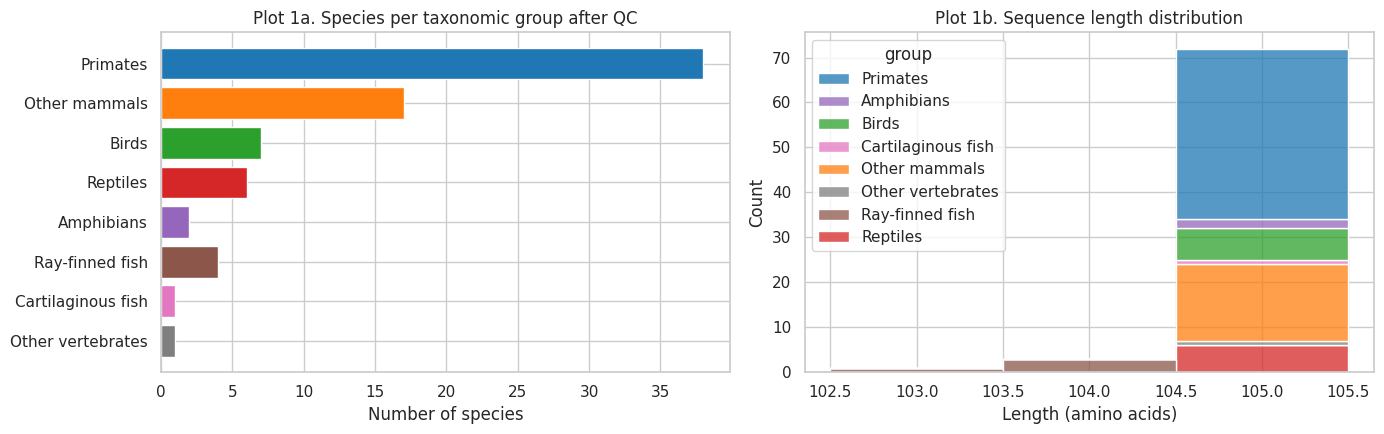

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = clean.group.value_counts().reindex(GROUP_ORDER).dropna()
axes[0].barh(order.index[::-1], order.values[::-1], color=[PALETTE[g] for g in order.index[::-1]])
axes[0].set(title="Plot 1a. Species per taxonomic group after QC", xlabel="Number of species")
sns.histplot(data=clean, x="length", hue="group", palette=PALETTE, multiple="stack", discrete=True, ax=axes[1])
axes[1].set(title="Plot 1b. Sequence length distribution", xlabel="Length (amino acids)")
plt.tight_layout(); plt.savefig("results/plot1_groups_lengths.png", dpi=150); plt.show()

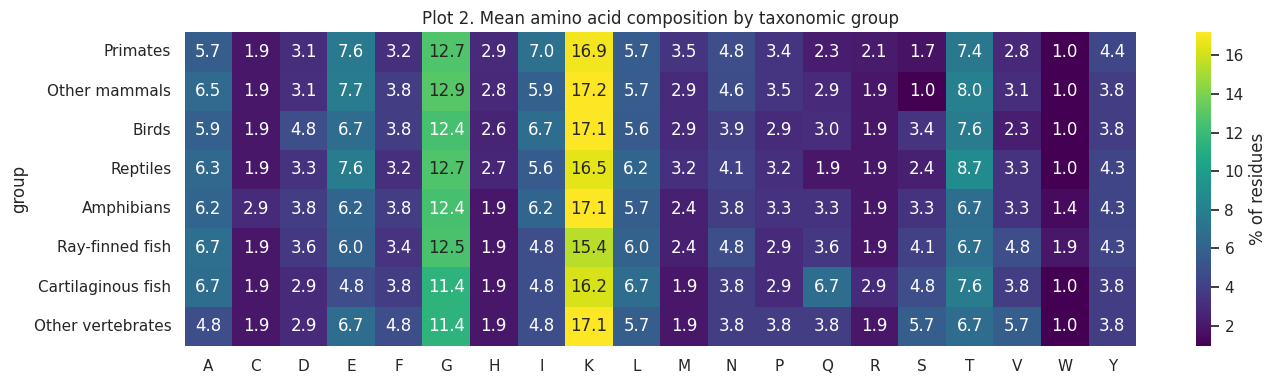

Most abundant residues overall (%): {'K': 16.9, 'G': 12.7, 'T': 7.6, 'E': 7.4}
Lysine + arginine (positively charged): 18.9% of residues


In [10]:
AA = list("ACDEFGHIKLMNPQRSTVWY")
comp = pd.DataFrame([{a: s.count(a) / len(s) * 100 for a in AA} for s in clean.sequence])
comp["group"] = clean.group.values
comp_mean = comp.groupby("group")[AA].mean().reindex(GROUP_ORDER)

plt.figure(figsize=(14, 4))
sns.heatmap(comp_mean, cmap="viridis", annot=True, fmt=".1f", cbar_kws={"label": "% of residues"})
plt.title("Plot 2. Mean amino acid composition by taxonomic group")
plt.tight_layout(); plt.savefig("results/plot2_composition.png", dpi=150); plt.show()

top_aa = comp[AA].mean().sort_values(ascending=False)
print("Most abundant residues overall (%):", top_aa.head(4).round(1).to_dict())
print(f"Lysine + arginine (positively charged): {top_aa[['K','R']].sum():.1f}% of residues")

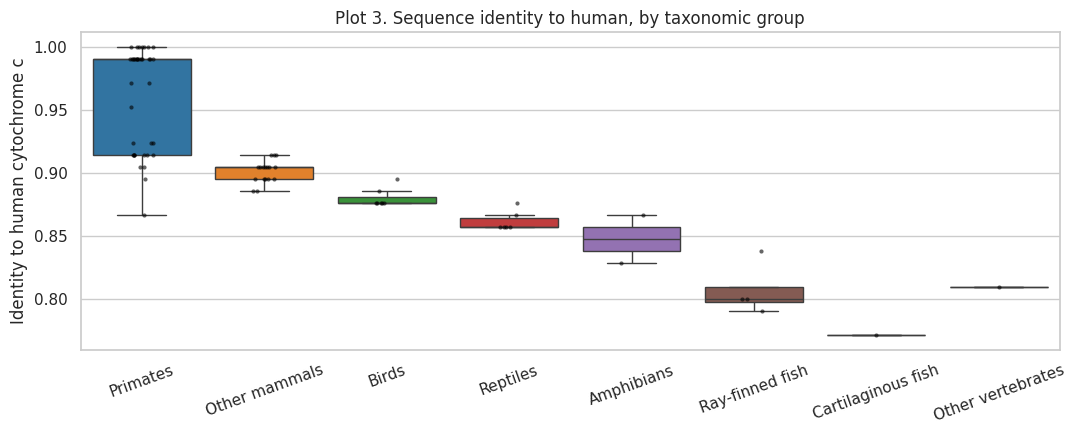

,count,mean,min,max
group,,,,
Primates,38,96.1,86.7,100.0
Other mammals,17,90.1,88.6,91.4
Birds,7,88.0,87.6,89.5
Reptiles,6,86.2,85.7,87.6
Amphibians,2,84.8,82.9,86.7
Ray-finned fish,4,80.7,79.0,83.8
Cartilaginous fish,1,77.1,77.1,77.1
Other vertebrates,1,81.0,81.0,81.0


In [11]:
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=clean, x="group", y="identity_to_human", order=GROUP_ORDER, palette=PALETTE, showfliers=False)
sns.stripplot(data=clean, x="group", y="identity_to_human", order=GROUP_ORDER, color="black", size=3, alpha=0.6)
plt.ylabel("Identity to human cytochrome c"); plt.xlabel("")
plt.title("Plot 3. Sequence identity to human, by taxonomic group")
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig("results/plot3_identity_to_human.png", dpi=150); plt.show()

id_by_group = clean.groupby("group").identity_to_human.agg(["count", "mean", "min", "max"]).reindex(GROUP_ORDER)
display((id_by_group.assign(**{c: id_by_group[c] * 100 for c in ["mean", "min", "max"]})).round(1))

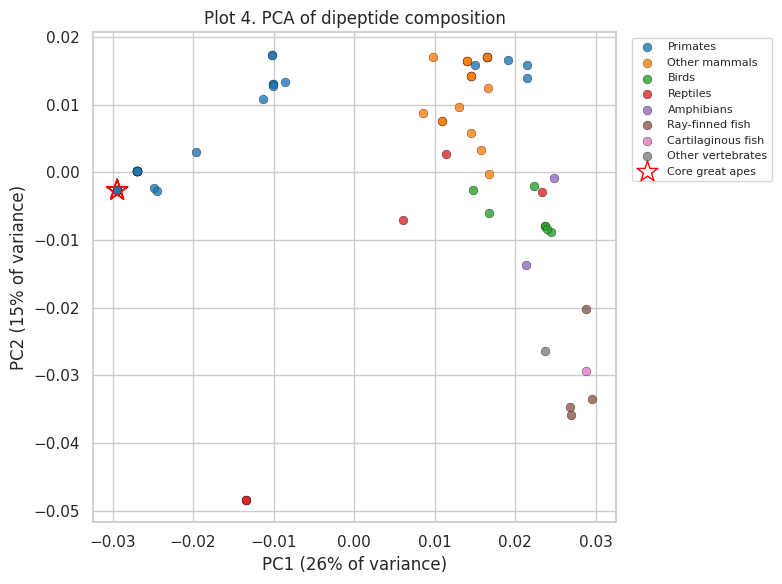

PC1 + PC2 explain 41% of the variance.


In [12]:
# PCA on dipeptide (2-mer) composition, which needs no alignment
DIPEP = [a + b for a in AA for b in AA]
def dipeptide_vector(s):
    c = Counter(s[i:i+2] for i in range(len(s) - 1))
    return [c[d] / (len(s) - 1) for d in DIPEP]

X_dp = np.array([dipeptide_vector(s) for s in clean.sequence])
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(X_dp)
plt.figure(figsize=(8, 6))
for g in GROUP_ORDER:
    m = (clean.group == g).values
    plt.scatter(pcs[m, 0], pcs[m, 1], label=g, color=PALETTE[g], s=40, alpha=0.8, edgecolor="k", linewidth=0.3)
core_m = clean.tier.eq("1 core").values
plt.scatter(pcs[core_m, 0], pcs[core_m, 1], marker="*", s=250, facecolor="none", edgecolor="red", label="Core great apes")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.title("Plot 4. PCA of dipeptide composition"); plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig("results/plot4_pca.png", dpi=150); plt.show()
print(f"PC1 + PC2 explain {pca.explained_variance_ratio_[:2].sum():.0%} of the variance.")

**Interpretation (EDA).** Plot 1 shows that the dataset is unbalanced: primates make up 38 of the 76 species and other mammals 17, while amphibians, cartilaginous fish (Puget Sound dogfish) and the one jawless vertebrate (Pacific lamprey) contribute only one or two species each. Lengths vary by at most two residues, confirming that we are comparing the same protein.

Plot 2 shows a very similar composition in every group, dominated by lysine (16.9 % of all residues; lysine and arginine together 18.9 %). This fits cytochrome c's biology: its ring of positively charged lysines helps it dock onto its negatively charged partners, complexes III and IV.

Plot 3 gives the clearest early signal. Mean identity to human falls in the order expected from vertebrate evolution: primates 96.1 %, other mammals 90.1 %, birds 88.0 %, reptiles 86.2 %, amphibians 84.8 %, ray-finned fish 80.7 % and the dogfish 77.1 %. This supports H2. Primates also span the widest range (86.7–100 %), a first hint that some primates are much less human-like than others, which Stage 5 explains.

In Plot 4 the first two principal components explain only 41 % of the variance. The core great apes sit exactly on top of one another because their sequences are identical, and groups overlap partly, so composition alone is a weak signal; the alignment-based analysis in Stage 5 is more informative.

## Stage 5 — Core analysis

5.1 Multiple sequence alignment (MAFFT) · 5.2 Core great-ape comparison · 5.3 Primate identity matrix · 5.4 Conserved and variable positions · 5.5 Statistical test of sequence distance against taxonomic distance · 5.6 Phylogenetic tree

In [13]:
# 5.1 Multiple sequence alignment with MAFFT
res = subprocess.run(["mafft", "--auto", "--quiet", "data/cytc_clean.fasta"], capture_output=True, text=True, check=True)
open("data/cytc_aligned.fasta", "w").write(res.stdout)
msa = AlignIO.read("data/cytc_aligned.fasta", "fasta")
aligned = {rec.id: str(rec.seq).upper() for rec in msa}
clean["aligned"] = clean.label.map(aligned)
L = msa.get_alignment_length()
gap_cols = sum("-" in "".join(s[i] for s in aligned.values()) for i in range(L))
print(f"Alignment: {len(msa)} sequences x {L} columns; {gap_cols} columns contain at least one gap")

human_label = clean.loc[clean.accession == HUMAN_ACC, "label"].iloc[0]
human_aln = aligned[human_label]
col_to_human, pos = {}, 0
for i, ch in enumerate(human_aln):
    if ch != "-":
        pos += 1
        col_to_human[i] = pos
human_to_col = {v: k for k, v in col_to_human.items()}

def aln_identity(a, b):
    cols = [(x, y) for x, y in zip(a, b) if not (x == "-" and y == "-")]
    diff = sum(x != y for x, y in cols)
    return 1 - diff / len(cols), diff

Alignment: 76 sequences x 105 columns; 2 columns contain at least one gap


In [14]:
# 5.2 Core comparison: human, chimpanzee, gorilla, orangutan
core = clean[clean.tier == "1 core"].copy()
core["name"] = core.common
names = core.name.tolist()
id_mat = pd.DataFrame(index=names, columns=names, dtype=float)
diff_mat = pd.DataFrame(index=names, columns=names, dtype=int)
for a in core.itertuples():
    for b in core.itertuples():
        idt, d = aln_identity(a.aligned, b.aligned)
        id_mat.loc[a.name, b.name], diff_mat.loc[a.name, b.name] = idt * 100, d

var_cols = [i for i in range(L) if len(set(s[i] for s in core.aligned)) > 1]
print("Core great apes - percent identity:")
display(id_mat.round(1))
print("Core great apes - number of amino acid differences:")
display(diff_mat)
if var_cols:
    display(pd.DataFrame({n: [s[i] for i in var_cols] for n, s in zip(names, core.aligned)},
                         index=[f"human pos {col_to_human.get(i, '-')}" for i in var_cols]))
else:
    print("Variable positions among the core great apes: NONE - the four sequences are identical.")
SUMMARY.update(core_min_identity=id_mat.values.min(), core_variable_positions=len(var_cols))

Core great apes - percent identity:


,Gorilla,Human,Chimpanzee,Sumatran orangutan
Gorilla,100.0,100.0,100.0,100.0
Human,100.0,100.0,100.0,100.0
Chimpanzee,100.0,100.0,100.0,100.0
Sumatran orangutan,100.0,100.0,100.0,100.0


Core great apes - number of amino acid differences:


,Gorilla,Human,Chimpanzee,Sumatran orangutan
Gorilla,0.0,0.0,0.0,0.0
Human,0.0,0.0,0.0,0.0
Chimpanzee,0.0,0.0,0.0,0.0
Sumatran orangutan,0.0,0.0,0.0,0.0


Variable positions among the core great apes: NONE - the four sequences are identical.


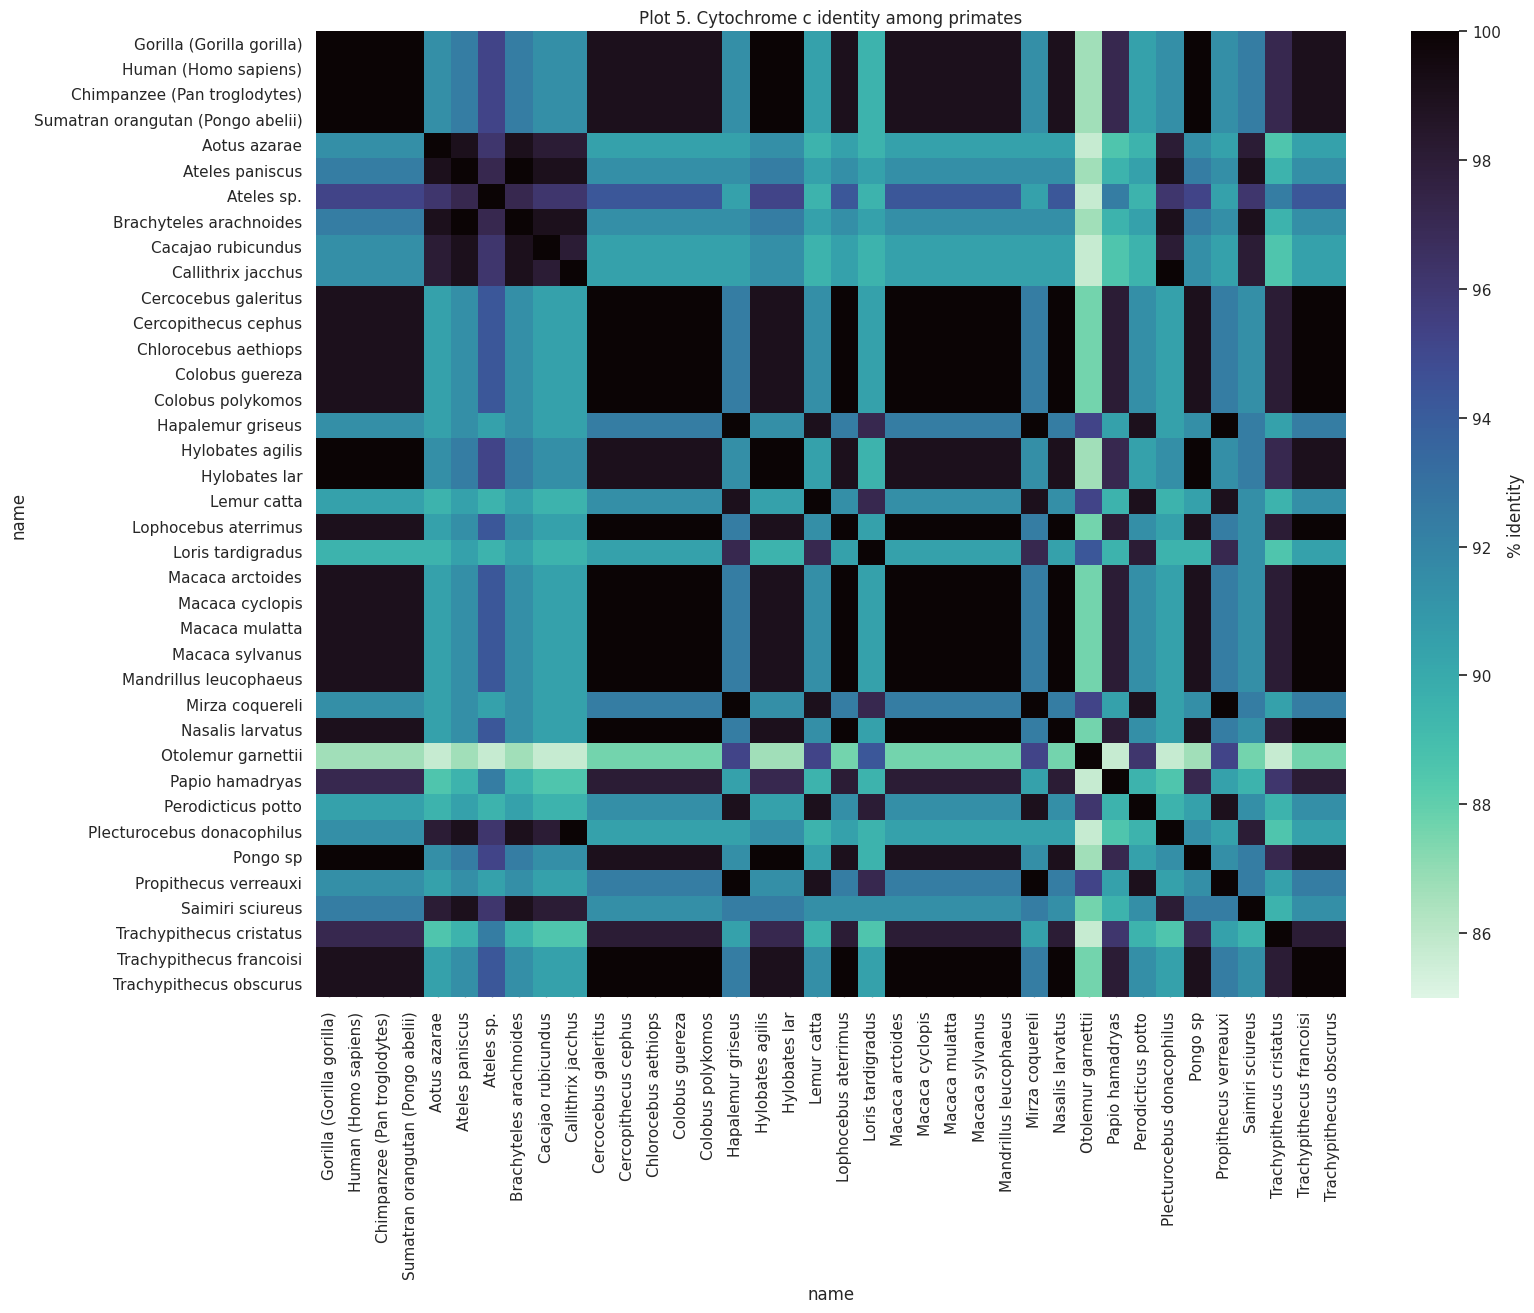

,name,tier,accession,reviewed,diffs_vs_human
0,Gorilla (Gorilla gorilla),1 core,Q6WUX8,reviewed,0
1,Human (Homo sapiens),1 core,P99999,reviewed,0
2,Chimpanzee (Pan troglodytes),1 core,P99998,reviewed,0
3,Sumatran orangutan (Pongo abelii),1 core,Q5RFH4,reviewed,0
17,Hylobates lar,2 primates,G4XXM6,unreviewed,0
16,Hylobates agilis,2 primates,G4XXM4,unreviewed,0
32,Pongo sp,2 primates,G4XXM3,unreviewed,0
12,Chlorocebus aethiops,2 primates,G4XXN2,unreviewed,1
14,Colobus polykomos,2 primates,G4XXM8,unreviewed,1
25,Mandrillus leucophaeus,2 primates,G4XXN7,unreviewed,1


In [15]:
# 5.3 Primate-wide identity matrix (tiers 1 and 2)
prim = clean[clean.group == "Primates"].copy()
prim["name"] = np.where(prim.common != "", prim.common + " (" + prim.species + ")", prim.species)
pm = np.array([[aln_identity(a, b)[0] * 100 for b in prim.aligned] for a in prim.aligned])
pm_df = pd.DataFrame(pm, index=prim.name, columns=prim.name)
h = max(4, 0.35 * len(prim))
plt.figure(figsize=(h + 3, h))
sns.heatmap(pm_df, cmap="mako_r", vmin=max(85, pm.min() - 1), vmax=100,
            annot=len(prim) <= 15, fmt=".0f", cbar_kws={"label": "% identity"})
plt.title("Plot 5. Cytochrome c identity among primates")
plt.tight_layout(); plt.savefig("results/plot5_primate_identity.png", dpi=150); plt.show()

prim["diffs_vs_human"] = [aln_identity(human_aln, s)[1] for s in prim.aligned]
prim_table = prim[["name", "tier", "accession", "reviewed", "diffs_vs_human"]].sort_values("diffs_vs_human")
display(prim_table)
SUMMARY.update(n_primates=len(prim), max_primate_diffs=int(prim.diffs_vs_human.max()))

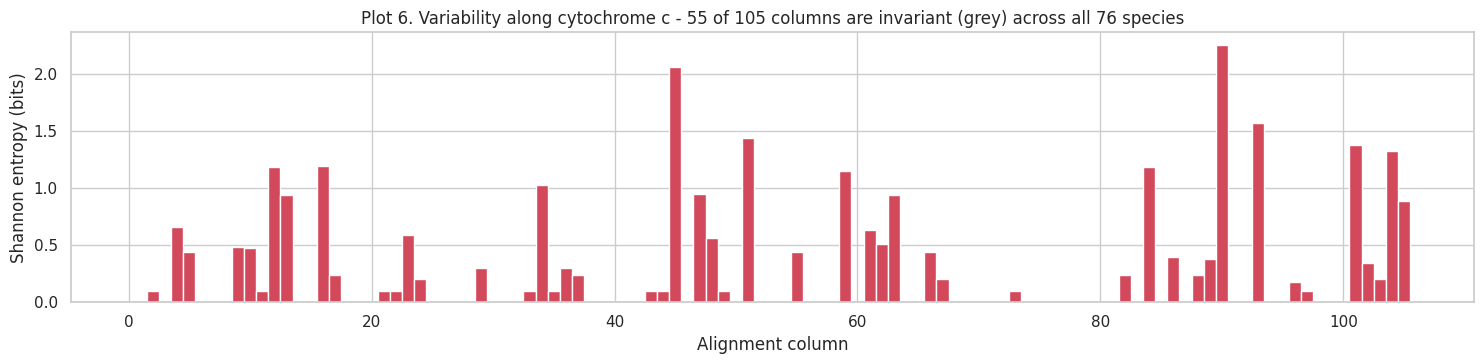

Most variable positions (human numbering):


,human_pos,human_aa,entropy,n_residue_types,pct_same_as_human
89,90,E,2.25,9,31.58
44,45,P,2.06,6,48.68
92,93,A,1.57,7,67.11
50,51,A,1.43,3,35.53
100,101,K,1.38,6,73.68
103,104,N,1.33,4,68.42
15,16,S,1.19,3,52.63
11,12,I,1.18,3,40.79
83,84,V,1.18,3,40.79
58,59,I,1.15,3,26.32


In [16]:
# 5.4 Conserved and variable positions across all vertebrates (Shannon entropy per column)
def column_stats(i):
    col = [s[i] for s in clean.aligned]
    res = [c for c in col if c != "-"]
    cnt = Counter(res)
    p = np.array(list(cnt.values())) / len(res)
    return {"column": i, "human_pos": col_to_human.get(i), "human_aa": human_aln[i],
            "entropy": float(-(p * np.log2(p)).sum()) + 0.0, "n_residue_types": len(cnt),
            "pct_same_as_human": 100 * sum(c == human_aln[i] for c in col) / len(col),
            "gaps": col.count("-")}

cons = pd.DataFrame([column_stats(i) for i in range(L)])
cons["invariant"] = (cons.n_residue_types == 1) & (cons.gaps == 0)
n_inv = int(cons.invariant.sum())

fig, ax = plt.subplots(figsize=(15, 3.8))
ax.bar(cons.column + 1, cons.entropy, color=np.where(cons.invariant, "#bbbbbb", "#d1495b"), width=1.0)
ax.set(xlabel="Alignment column", ylabel="Shannon entropy (bits)",
       title=f"Plot 6. Variability along cytochrome c - {n_inv} of {L} columns are invariant (grey) across all {len(clean)} species")
plt.tight_layout(); plt.savefig("results/plot6_entropy.png", dpi=150); plt.show()

print("Most variable positions (human numbering):")
display(cons.sort_values("entropy", ascending=False).head(10)[["human_pos", "human_aa", "entropy", "n_residue_types", "pct_same_as_human"]].round(2))
SUMMARY.update(n_invariant=n_inv, aln_len=L)

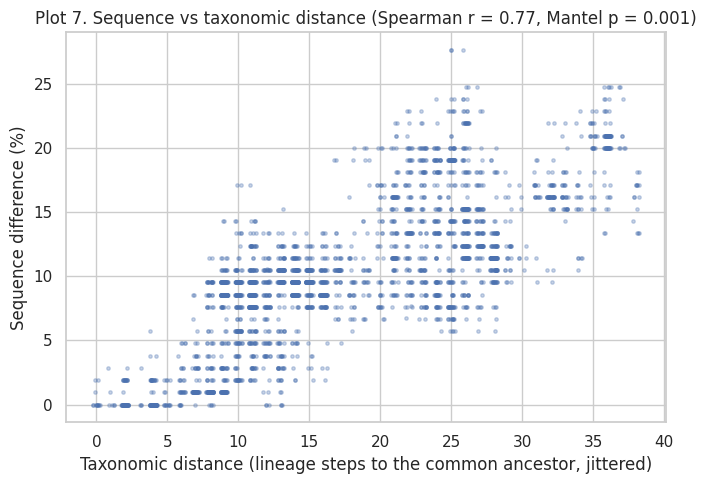

Mantel test (999 permutations): Spearman r = 0.765, p = 0.0010


In [17]:
# 5.5 Does sequence distance track taxonomic distance? Mantel test with Spearman correlation
labels = clean.label.tolist()
n = len(labels)
D_seq = np.zeros((n, n)); D_tax = np.zeros((n, n))
lineages = [clean_lineage(x) for x in clean.lineage]
for i in range(n):
    for j in range(i + 1, n):
        D_seq[i, j] = D_seq[j, i] = 1 - aln_identity(clean.aligned[i], clean.aligned[j])[0]
        a, b = lineages[i], lineages[j]
        shared = 0
        for x, y in zip(a, b):
            if x != y: break
            shared += 1
        D_tax[i, j] = D_tax[j, i] = (len(a) - shared) + (len(b) - shared)

def mantel(A, B, perms=999, seed=SEED):
    iu = np.triu_indices(A.shape[0], 1)
    r_obs = spearmanr(A[iu], B[iu]).correlation
    rng = np.random.default_rng(seed)
    hits = sum(spearmanr(A[iu], B[p][:, p][iu]).correlation >= r_obs
               for p in (rng.permutation(A.shape[0]) for _ in range(perms)))
    return r_obs, (hits + 1) / (perms + 1)

r_mantel, p_mantel = mantel(D_seq, D_tax)
iu = np.triu_indices(n, 1)
plt.figure(figsize=(7, 5))
plt.scatter(D_tax[iu] + np.random.uniform(-0.25, 0.25, len(iu[0])), D_seq[iu] * 100, s=6, alpha=0.3)
plt.xlabel("Taxonomic distance (lineage steps to the common ancestor, jittered)")
plt.ylabel("Sequence difference (%)")
plt.title(f"Plot 7. Sequence vs taxonomic distance (Spearman r = {r_mantel:.2f}, Mantel p = {p_mantel:.3f})")
plt.tight_layout(); plt.savefig("results/plot7_mantel.png", dpi=150); plt.show()
print(f"Mantel test (999 permutations): Spearman r = {r_mantel:.3f}, p = {p_mantel:.4f}")
SUMMARY.update(mantel_r=r_mantel, mantel_p=p_mantel)

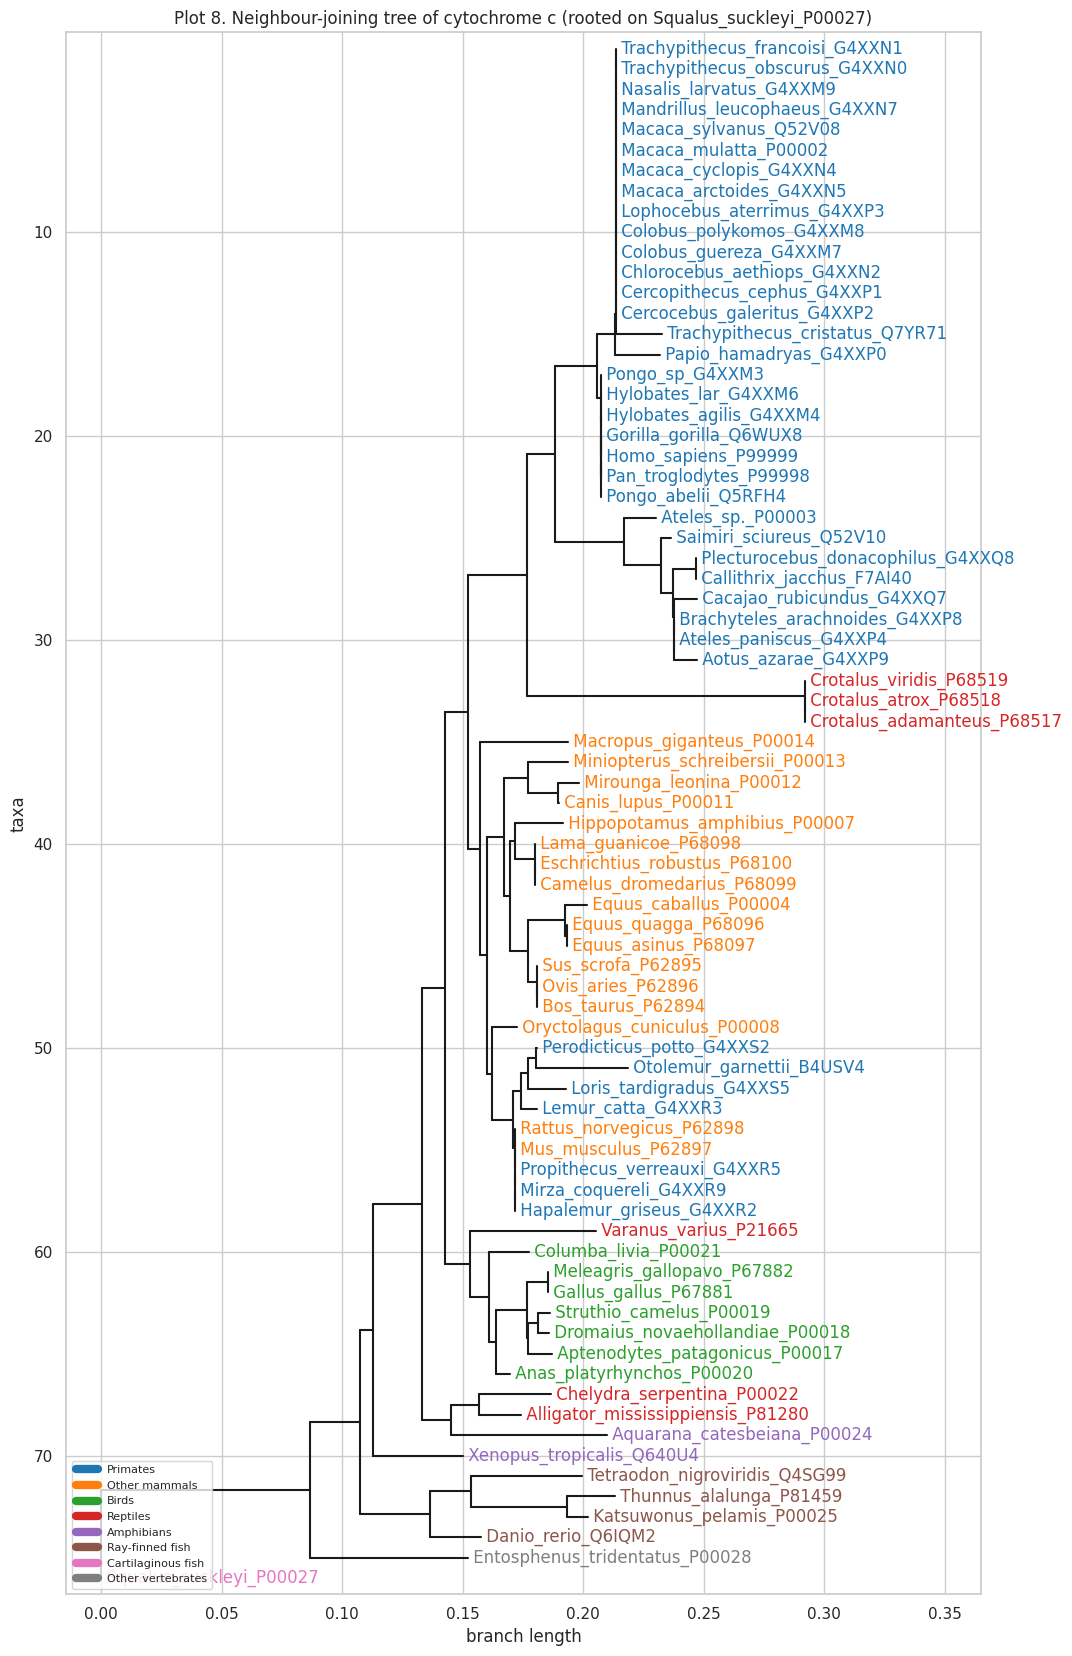

,group,n,monophyletic,other groups inside clade
0,Primates,38,False,"Reptiles (3), Other mammals (17)"
1,Other mammals,17,False,Primates (7)
2,Birds,7,True,-
3,Reptiles,6,False,"Primates (38), Other mammals (17), Birds (7), Amphibians (1)"
4,Amphibians,2,False,"Primates (38), Reptiles (6), Other mammals (17), Birds (7)"
5,Ray-finned fish,4,True,-


In [18]:
# 5.6 Neighbour-joining tree from identity distances, rooted on the most divergent sequence
tree = DistanceTreeConstructor().nj(DistanceCalculator("identity").get_distance(msa))
outgroup = clean.sort_values("identity_to_human").label.iloc[0]
tree.root_with_outgroup(outgroup)
Phylo.write(tree, "results/cytc_nj_tree.nwk", "newick")

lab2group = dict(zip(clean.label, clean.group))
fig, ax = plt.subplots(figsize=(11, max(8, 0.22 * n)))
Phylo.draw(tree, axes=ax, do_show=False,
           label_func=lambda c: c.name if c.is_terminal() else None,
           label_colors=lambda name: PALETTE.get(lab2group.get(name), "black"))
for g in GROUP_ORDER:
    ax.plot([], [], color=PALETTE[g], lw=6, label=g)
ax.legend(loc="lower left", fontsize=8)
ax.set_title(f"Plot 8. Neighbour-joining tree of cytochrome c (rooted on {outgroup})")
plt.tight_layout(); plt.savefig("results/plot8_nj_tree.png", dpi=150); plt.show()

mono = []
for g in GROUP_ORDER:
    members = [t for t in tree.get_terminals() if lab2group.get(t.name) == g]
    if len(members) >= 2:
        ca = tree.common_ancestor(members)
        extra = [lab2group[t.name] for t in ca.get_terminals() if lab2group[t.name] != g]
        mono.append({"group": g, "n": len(members), "monophyletic": not extra,
                     "other groups inside clade": ", ".join(f"{k} ({v})" for k, v in Counter(extra).items()) or "-"})
mono_df = pd.DataFrame(mono)
display(mono_df)
SUMMARY.update(mono=mono_df)

In [19]:
# Results table: mean identity to human and differences by group
res_table = (clean.assign(diffs=[aln_identity(human_aln, s)[1] for s in clean.aligned])
             .groupby("group").agg(species=("species", "count"),
                                   mean_identity_pct=("identity_to_human", lambda x: 100 * x.mean()),
                                   mean_differences=("diffs", "mean"), min_diff=("diffs", "min"), max_diff=("diffs", "max"))
             .reindex(GROUP_ORDER).round(1))
display(res_table)
res_table.to_csv("results/table_identity_by_group.csv")

print("\nAuto-summary of core results:")
print(f" - Core great apes: minimum pairwise identity {SUMMARY['core_min_identity']:.1f}%, "
      f"{SUMMARY['core_variable_positions']} variable positions.")
print(f" - Primates ({SUMMARY['n_primates']} species): at most {SUMMARY['max_primate_diffs']} differences from human.")
print(f" - All vertebrates: {SUMMARY['n_invariant']} of {SUMMARY['aln_len']} alignment columns invariant.")
print(f" - Sequence vs taxonomic distance: r = {SUMMARY['mantel_r']:.2f}, p = {SUMMARY['mantel_p']:.4f}.")
print(" - Groups recovered as single clades in the tree:", ", ".join(mono_df[mono_df.monophyletic].group) or "none")

,species,mean_identity_pct,mean_differences,min_diff,max_diff
group,,,,,
Primates,38,96.1,4.1,0,14
Other mammals,17,90.1,10.4,9,12
Birds,7,88.0,12.6,11,13
Reptiles,6,86.2,14.5,13,15
Amphibians,2,84.8,16.0,14,18
Ray-finned fish,4,80.7,20.2,17,22
Cartilaginous fish,1,77.1,24.0,24,24
Other vertebrates,1,81.0,20.0,20,20



Auto-summary of core results:
 - Core great apes: minimum pairwise identity 100.0%, 0 variable positions.
 - Primates (38 species): at most 14 differences from human.
 - All vertebrates: 55 of 105 alignment columns invariant.
 - Sequence vs taxonomic distance: r = 0.77, p = 0.0010.
 - Groups recovered as single clades in the tree: Birds, Ray-finned fish


**Interpretation (core analysis).** Human, chimpanzee, gorilla and orangutan cytochrome c are **100 % identical**, with no variable positions, and two gibbon species share the same sequence. H1 is supported in its strongest form, and it answers the first half of the research question: within the great apes, the protein carries no information about which species are most closely related.

Widening to 38 primates shows where change begins. Old World monkeys differ from human at 1–3 positions, New World monkeys at 5–9, and the strepsirrhines (lemurs, lorises and galagos) at 9–14, as many as non-primate mammals (9–12). Across all 76 vertebrates, 55 of the 105 alignment positions are invariant.

The Mantel test shows a strong, significant positive correlation between sequence distance and taxonomic distance (Spearman r = 0.77, p = 0.001 over 999 permutations), supporting H2. The neighbour-joining tree agrees only in part. Birds and ray-finned fish each form a clean clade, and the anthropoid primates (apes, Old World monkeys and New World monkeys) group together. However, the strepsirrhine primates group with rodents and other mammals rather than with other primates, and the three rattlesnake sequences fall beside the anthropoids rather than with the other reptiles.

The strepsirrhine result has a known biological explanation. Cytochrome c and its partner proteins underwent a burst of accelerated evolution in the anthropoid lineage (Grossman et al., 2004; Schmidt et al., 2005). Anthropoids therefore carry many derived changes, while lemurs and lorises keep a sequence close to the ancestral mammalian one; three lemurs have exactly the mouse and rat sequence. The rattlesnake placement is most likely an artefact of building a tree from a single short protein, where unusual changes in one lineage can pull it to the wrong position. Overall, cytochrome c reflects evolutionary relationships at a broad scale but is unreliable for fine-scale relationships, including those within primates.

## Stage 6 — Biological interpretation

Two interpretation methods are used: **functional-site annotation** (mapping UniProt's annotated sites of human cytochrome c onto our conservation results) and **comparison with published findings**.

In [20]:
FALLBACK_FEATURES = [  # from the UniProt P99999 entry, used only if the live download fails
    {"feature": "Binding site", "description": "heme c (covalent)", "position": 15},
    {"feature": "Binding site", "description": "heme c (covalent)", "position": 18},
    {"feature": "Binding site", "description": "heme c (axial binding residue)", "position": 19},
    {"feature": "Binding site", "description": "heme c (axial binding residue)", "position": 81},
]
def load_features():
    path = "data/P99999_features.json"
    try:
        if os.path.exists(path):
            data = json.load(open(path))
        else:
            data = polite_get("https://rest.uniprot.org/uniprotkb/P99999.json").json(); json.dump(data, open(path, "w"))
        rows = []
        for f in data.get("features", []):
            if f.get("type") not in ("Binding site", "Modified residue", "Site"):
                continue
            s, e = f["location"]["start"]["value"], f["location"]["end"]["value"]
            desc = f.get("description") or (f.get("ligand") or {}).get("name", "")
            if (f.get("ligand") or {}).get("name") and f.get("description"):
                desc = f"{f['ligand']['name']} ({f['description']})"
            elif (f.get("ligand") or {}).get("name"):
                desc = f["ligand"]["name"]
            for p in range(int(s), int(e) + 1):
                rows.append({"feature": f["type"], "description": desc, "position": p})
        return pd.DataFrame(rows), "UniProt P99999 (downloaded)"
    except Exception as ex:
        print("Live annotation unavailable, using stored annotation:", ex)
        return pd.DataFrame(FALLBACK_FEATURES), "UniProt P99999 (stored copy)"

feat, feat_src = load_features()
feat = feat.drop_duplicates(["feature", "position"])
feat["human_aa"] = feat.position.map(lambda p: human_seq[p - 1])
feat["column"] = feat.position.map(human_to_col)
feat = feat.merge(cons[["column", "entropy", "pct_same_as_human", "invariant"]], on="column", how="left")
print("Annotation source:", feat_src)
display(feat.sort_values("position").round(1))

site_cols = set(feat.column.dropna().astype(int))
in_site = cons[cons.column.isin(site_cols)].entropy
off_site = cons[~cons.column.isin(site_cols)].entropy
u = mannwhitneyu(in_site, off_site, alternative="less") if len(in_site) > 1 else None
print(f"\nMean entropy at annotated functional sites: {in_site.mean():.3f} bits vs {off_site.mean():.3f} bits elsewhere"
      + (f" (Mann-Whitney one-sided p = {u.pvalue:.4f})" if u else ""))
heme = feat[feat.description.str.contains("heme", case=False, na=False)]
print(f"Heme-binding residues invariant across all species: {int(heme.invariant.sum())}/{len(heme)}")
SUMMARY.update(heme_invariant=f"{int(heme.invariant.sum())}/{len(heme)}", site_entropy=in_site.mean(), other_entropy=off_site.mean())

Annotation source: UniProt P99999 (downloaded)


,feature,description,position,human_aa,column,entropy,pct_same_as_human,invariant
4,Modified residue,N-acetylglycine,2,G,1,0.1,98.7,False
0,Binding site,heme c (covalent),15,C,14,0.0,100.0,True
1,Binding site,heme c (covalent),18,C,17,0.0,100.0,True
2,Binding site,heme c (axial binding residue),19,H,18,0.0,100.0,True
5,Modified residue,Phosphotyrosine,49,Y,48,0.1,98.7,False
6,Modified residue,N6-succinyllysine,56,K,55,0.0,100.0,True
7,Modified residue,N6-acetyllysine; alternate,73,K,72,0.1,98.7,False
3,Binding site,heme c (axial binding residue),81,M,80,0.0,100.0,True
8,Modified residue,Phosphotyrosine,98,Y,97,0.0,100.0,True
9,Modified residue,N6-acetyllysine,100,K,99,0.0,100.0,True



Mean entropy at annotated functional sites: 0.030 bits vs 0.305 bits elsewhere (Mann-Whitney one-sided p = 0.0438)
Heme-binding residues invariant across all species: 4/4


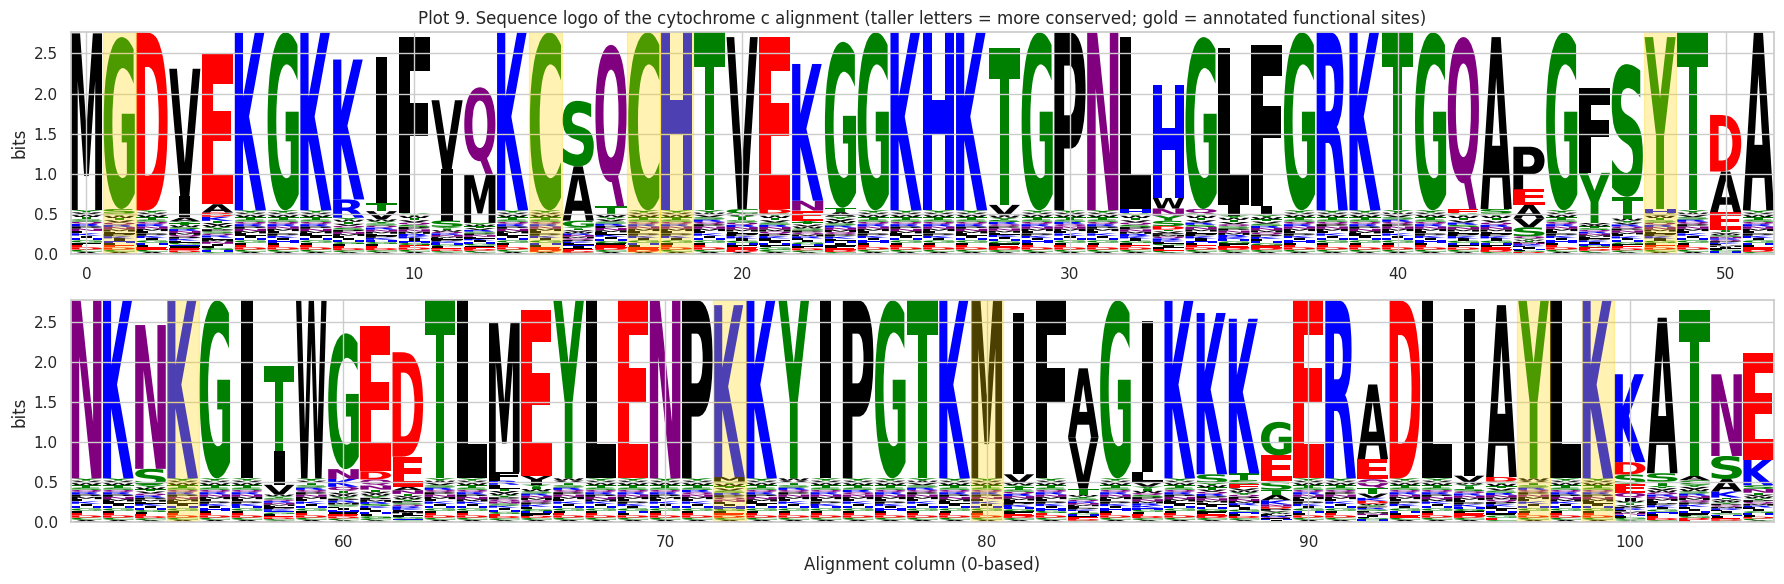

In [21]:
logo_df = logomaker.alignment_to_matrix(clean.aligned.tolist(), to_type="information")
half = L // 2
fig, axes = plt.subplots(2, 1, figsize=(18, 6))
for ax, (a, b) in zip(axes, [(0, half), (half, L)]):
    logomaker.Logo(logo_df.iloc[a:b], ax=ax, color_scheme="chemistry")
    for c in site_cols:
        if a <= c < b:
            ax.axvspan(c - 0.5, c + 0.5, color="gold", alpha=0.3)
    ax.set_ylabel("bits")
axes[0].set_title("Plot 9. Sequence logo of the cytochrome c alignment (taller letters = more conserved; gold = annotated functional sites)")
axes[1].set_xlabel("Alignment column (0-based)")
plt.tight_layout(); plt.savefig("results/plot9_logo.png", dpi=150); plt.show()

**Interpretation (biology).** Cytochrome c carries electrons from complex III to complex IV in the mitochondrial electron transport chain and, when released into the cytoplasm, triggers apoptosis. Both jobs depend on the heme group, which is held by two covalent bonds to Cys15 and Cys18 of the CXXCH motif, with its iron held between His19 and Met81 (UniProt numbering; His18 and Met80 in the mature protein). The annotation table shows that all four heme-binding residues are invariant across all 76 species, as are three of the six annotated modification sites (positions 56, 98 and 100); the other three change in only one species each (98.7 % identical to human). Annotated functional sites are less variable than the rest of the protein (mean entropy 0.030 vs 0.305 bits; one-sided Mann-Whitney p = 0.044), although with only ten annotated sites this test is modest. This is the mechanism behind the conservation measured in Stage 5: changes at these positions would stop the protein working, so natural selection removes them. The most variable positions (for example human positions 90, 45 and 93) lie away from the heme-binding residues.

**Comparison with published findings.** Our results agree with the classic findings that human and chimpanzee cytochrome c are identical and that human and rhesus macaque differ at a single position (our data: 1 difference). The overall pattern, with differences from human increasing from other mammals (9–12) to birds (11–13), reptiles (13–15), amphibians (14–18), ray-finned fish (17–22) and the dogfish (24), matches the classic comparative tables of cytochrome c evolution (Margoliash, 1963; Dickerson, 1971). Our finding that strepsirrhine primates are no closer to humans than rodents are agrees with published evidence that cytochrome c evolved unusually fast in the anthropoid lineage, possibly linked to the high energy demands of the enlarged anthropoid brain (Grossman et al., 2004; Schmidt et al., 2005).

## Stage 7 — Machine learning

**Task:** predict the taxonomic group of a cytochrome c sequence from the sequence alone (H3).

**Design decisions**
- **Features:** the amino acid at each variable alignment column, one-hot encoded inside the cross-validation pipeline so that no information leaks from test folds.
- **Duplicates:** identical sequences within the same group are reduced to one, otherwise copies in both training and test folds would inflate accuracy.
- **Small groups:** groups with fewer than 5 sequences are merged into "Other vertebrates" so every class can appear in every fold.
- **Baselines:** (1) majority class — the score obtained without reading the sequence; (2) 1-nearest neighbour by percent identity — the "most similar sequence" rule a biologist would use without ML.
- **Models:** logistic regression and random forest, both with balanced class weights.
- **Evaluation:** repeated stratified k-fold cross-validation (10 repeats); balanced accuracy and macro F1, which are fair under class imbalance; a permutation test; a confusion matrix.
- **Unsupervised companion:** hierarchical clustering of the distance matrix, compared with true groups using the adjusted Rand index (ARI).

In [22]:
ml = clean.drop_duplicates(["aligned", "group"]).copy()
counts = ml.group.value_counts()
small = counts[counts < 5].index
ml["y"] = ml.group.where(~ml.group.isin(small), "Other vertebrates")
counts = ml.y.value_counts()
dropped = counts[counts < 3].index.tolist()
ml = ml[~ml.y.isin(dropped)].reset_index(drop=True)
print("Merged into 'Other vertebrates':", list(small) or "none", "| dropped (too few):", dropped or "none")
print("Class sizes used for ML:", ml.y.value_counts().to_dict())

X_chars = np.array([list(s) for s in ml.aligned])
var_mask = np.array([len(set(X_chars[:, j])) > 1 for j in range(X_chars.shape[1])])
X_chars = X_chars[:, var_mask]
var_columns = np.where(var_mask)[0]
y = ml.y.values
char_codes = {c: i for i, c in enumerate(sorted(set(X_chars.ravel())))}
X_int = np.vectorize(char_codes.get)(X_chars)
k = int(min(5, ml.y.value_counts().min()))
print(f"{len(ml)} sequences, {X_chars.shape[1]} variable columns as features, {k}-fold cross-validation x 10 repeats")

Merged into 'Other vertebrates': ['Ray-finned fish', 'Reptiles', 'Amphibians', 'Cartilaginous fish', 'Other vertebrates'] | dropped (too few): none
Class sizes used for ML: {'Primates': 15, 'Other vertebrates': 12, 'Other mammals': 11, 'Birds': 6}
44 sequences, 50 variable columns as features, 5-fold cross-validation x 10 repeats


,model,balanced_accuracy,macro_F1
0,Baseline: majority class,0.250 ± 0.000,0.127 ± 0.005
1,Baseline: 1-nearest neighbour (identity),0.797 ± 0.118,0.771 ± 0.150
2,Logistic regression,0.917 ± 0.100,0.899 ± 0.130
3,Random forest,0.901 ± 0.110,0.877 ± 0.141


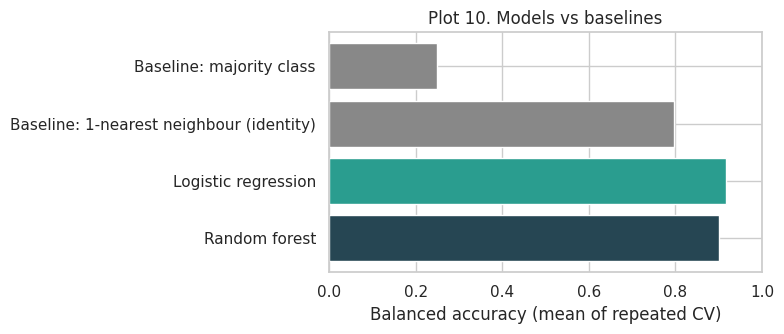

Permutation test for Logistic regression: balanced accuracy 0.933; shuffled-label mean 0.241; p = 0.0099


In [23]:
def ohe_pipe(clf):
    return Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore")), ("clf", clf)])

models = {
    "Baseline: majority class": (DummyClassifier(strategy="most_frequent"), X_int),
    "Baseline: 1-nearest neighbour (identity)": (KNeighborsClassifier(n_neighbors=1, metric="hamming"), X_int),
    "Logistic regression": (ohe_pipe(LogisticRegression(max_iter=5000, class_weight="balanced", C=1.0)), X_chars),
    "Random forest": (ohe_pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1)), X_chars),
}
cv = RepeatedStratifiedKFold(n_splits=k, n_repeats=10, random_state=SEED)
rows = []
for name, (m, X) in models.items():
    s = cross_validate(m, X, y, cv=cv, scoring=["balanced_accuracy", "f1_macro"])
    rows.append({"model": name,
                 "balanced_accuracy": f"{s['test_balanced_accuracy'].mean():.3f} ± {s['test_balanced_accuracy'].std():.3f}",
                 "macro_F1": f"{s['test_f1_macro'].mean():.3f} ± {s['test_f1_macro'].std():.3f}",
                 "_bacc": s["test_balanced_accuracy"].mean()})
ml_results = pd.DataFrame(rows)
display(ml_results.drop(columns="_bacc"))
ml_results.drop(columns="_bacc").to_csv("results/table_ml_results.csv", index=False)

plt.figure(figsize=(8, 3.5))
plt.barh(ml_results.model[::-1], ml_results._bacc[::-1], color=["#888", "#888", "#2a9d8f", "#264653"][::-1])
plt.xlabel("Balanced accuracy (mean of repeated CV)"); plt.xlim(0, 1)
plt.title("Plot 10. Models vs baselines"); plt.tight_layout(); plt.savefig("results/plot10_ml.png", dpi=150); plt.show()

best_name = ml_results.iloc[2:].sort_values("_bacc").model.iloc[-1]
best_model, best_X = models[best_name]
score, perm_scores, p_perm = permutation_test_score(best_model, best_X, y, scoring="balanced_accuracy",
                             cv=StratifiedKFold(k, shuffle=True, random_state=SEED), n_permutations=100, random_state=SEED, n_jobs=-1)
print(f"Permutation test for {best_name}: balanced accuracy {score:.3f}; "
      f"shuffled-label mean {perm_scores.mean():.3f}; p = {p_perm:.4f}")
SUMMARY.update(ml_table=ml_results, best_model=best_name, perm_p=p_perm)

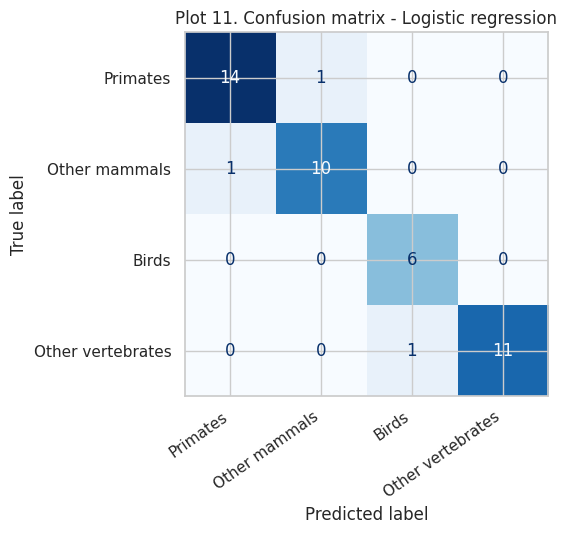

,alignment_column,importance,human_position,human_aa,residues_seen
0,104,0.107,105,E,-EKNS
1,103,0.096,104,N,AKNS
2,3,0.084,4,V,AIV
3,44,0.083,45,P,AEPQSV
4,15,0.074,16,S,AGS
5,89,0.062,90,E,ADEGKNPST
6,100,0.060,101,K,DEIKQS
7,62,0.052,63,D,ADEN
8,50,0.046,51,A,ADE
9,83,0.039,84,V,ATV


In [24]:
pred = cross_val_predict(best_model, best_X, y, cv=StratifiedKFold(k, shuffle=True, random_state=SEED))
classes = [g for g in GROUP_ORDER + ["Other vertebrates"] if g in set(y)]
classes = list(dict.fromkeys(classes))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=classes), display_labels=classes).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Plot 11. Confusion matrix - {best_name}"); plt.xticks(rotation=35, ha="right")
plt.tight_layout(); plt.savefig("results/plot11_confusion.png", dpi=150); plt.show()

rf = models["Random forest"][0].fit(X_chars, y)
fn = rf.named_steps["onehot"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=fn)
col_idx = imp.index.str.extract(r"^x(\d+)_")[0].astype(int).values
imp_by_col = pd.Series(imp.values).groupby(col_idx).sum().sort_values(ascending=False)
top = pd.DataFrame({"alignment_column": var_columns[imp_by_col.index[:10]],
                    "importance": imp_by_col.values[:10]})
top["human_position"] = top.alignment_column.map(col_to_human)
top["human_aa"] = top.alignment_column.map(lambda c: human_aln[c])
top["residues_seen"] = top.alignment_column.map(lambda c: "".join(sorted(set(s[c] for s in ml.aligned))))
display(top.round(3))

In [25]:
idx = ml.index.values
lab_pos = {l: i for i, l in enumerate(clean.label)}
sub = [lab_pos[l] for l in ml.label]
D_ml = D_seq[np.ix_(sub, sub)]
n_clusters = len(set(y))
clusters = AgglomerativeClustering(n_clusters=n_clusters, metric="precomputed", linkage="average").fit_predict(D_ml)
ari = adjusted_rand_score(y, clusters)
rng = np.random.default_rng(SEED)
null = np.array([adjusted_rand_score(rng.permutation(y), clusters) for _ in range(1000)])
p_ari = (np.sum(null >= ari) + 1) / 1001
print(f"Hierarchical clustering into {n_clusters} clusters: ARI = {ari:.3f} "
      f"(random baseline {null.mean():.3f}, permutation p = {p_ari:.4f})")
display(pd.crosstab(pd.Series(y, name="true group"), pd.Series(clusters, name="cluster")))
SUMMARY.update(ari=ari, ari_p=p_ari)

Hierarchical clustering into 4 clusters: ARI = 0.052 (random baseline 0.000, permutation p = 0.0170)


cluster,0,1,2,3
true group,,,,
Birds,6,0,0,0
Other mammals,11,0,0,0
Other vertebrates,6,4,1,1
Primates,15,0,0,0


**Interpretation (machine learning).** After removing identical sequences within each group and merging small groups, the models used 44 sequences in four classes: primates (15), other mammals (11), birds (6) and "other vertebrates" (12, combining reptiles, amphibians, fish and the lamprey). Logistic regression performed best, with a balanced accuracy of 0.917 ± 0.100, against 0.250 for the majority-class baseline and 0.797 ± 0.118 for the 1-nearest-neighbour baseline. The permutation test (p = 0.0099) shows this is very unlikely to be chance, so H3 is supported. The random forest performed similarly (0.901 ± 0.110).

The confusion matrix shows only three errors out of 44, and each has a biological explanation. The house mouse was predicted as a primate because its sequence is identical to that of three lemurs, so no model could separate them. The ring-tailed lemur was predicted as another mammal, because strepsirrhine primates keep a sequence close to the ancestral mammalian one (Stage 5). The lace monitor, a reptile in the "other vertebrates" class, was predicted as a bird, which is sensible since birds and reptiles are close relatives. The most important features are variable positions such as human positions 4, 16, 45 and 90, not the heme-binding residues, which are invariant and so carry no group information. The top feature, position 105, partly reflects the four fish sequences ending one residue early, a gap rather than a substitution.

The unsupervised clustering did **not** recover the taxonomic groups (adjusted Rand index 0.05). Although slightly above the random baseline (p = 0.017), it placed 38 of the 44 sequences in one cluster and separated only a few divergent fish and other vertebrates. Without labels, overall similarity is dominated by a few very different sequences, so supervised learning was needed to read group membership from the variable positions.

**Limitations of this stage.** The dataset is small, so scores vary widely between folds (standard deviations around 0.10). Species share ancestry and are not independent samples, and the "other vertebrates" class combines quite different animals. The scores describe how well taxonomic group can be read from this protein in this dataset; they are not a validated tool for classifying new organisms.

## Stage 8 — Conclusions

In [26]:
mono_ok = ", ".join(SUMMARY["mono"][SUMMARY["mono"].monophyletic].group) or "none"
mlt = SUMMARY["ml_table"].set_index("model")
print("Objective 1 - Data retrieval:")
print(f"  {SUMMARY['n_raw']} UniProt records downloaded; {SUMMARY['n_core']}/4 core great-ape records retrieved and documented "
      f"with accession numbers, review status and retrieval date.")
print("Objective 2 - Quality control and alignment:")
print(f"  {SUMMARY['n_clean']} species passed the 7-step checklist ({SUMMARY['n_unique_seq']} distinct sequences) "
      f"and were aligned with MAFFT ({SUMMARY['aln_len']} columns).")
print("Objective 3 - Identity, conserved and variable positions:")
print(f"  Core great apes: minimum identity {SUMMARY['core_min_identity']:.1f}%, {SUMMARY['core_variable_positions']} variable positions. "
      f"Primates differ from human at no more than {SUMMARY['max_primate_diffs']} positions. "
      f"{SUMMARY['n_invariant']}/{SUMMARY['aln_len']} columns are invariant across all vertebrates; "
      f"heme-binding residues invariant: {SUMMARY['heme_invariant']}.")
print("Objective 4 - Evolutionary relationships:")
print(f"  Sequence distance vs taxonomic distance: Spearman r = {SUMMARY['mantel_r']:.2f} (Mantel p = {SUMMARY['mantel_p']:.4f}). "
      f"Groups recovered as single clades: {mono_ok}. "
      f"Best model ({SUMMARY['best_model']}) balanced accuracy {mlt.loc[SUMMARY['best_model'], 'balanced_accuracy']} vs "
      f"majority baseline {mlt.loc['Baseline: majority class', 'balanced_accuracy']} and 1-NN "
      f"{mlt.loc['Baseline: 1-nearest neighbour (identity)', 'balanced_accuracy']} (permutation p = {SUMMARY['perm_p']:.4f}); "
      f"clustering ARI = {SUMMARY['ari']:.2f}.")

Objective 1 - Data retrieval:
  151 UniProt records downloaded; 4/4 core great-ape records retrieved and documented with accession numbers, review status and retrieval date.
Objective 2 - Quality control and alignment:
  76 species passed the 7-step checklist (43 distinct sequences) and were aligned with MAFFT (105 columns).
Objective 3 - Identity, conserved and variable positions:
  Core great apes: minimum identity 100.0%, 0 variable positions. Primates differ from human at no more than 14 positions. 55/105 columns are invariant across all vertebrates; heme-binding residues invariant: 4/4.
Objective 4 - Evolutionary relationships:
  Sequence distance vs taxonomic distance: Spearman r = 0.77 (Mantel p = 0.0010). Groups recovered as single clades: Birds, Ray-finned fish. Best model (Logistic regression) balanced accuracy 0.917 ± 0.100 vs majority baseline 0.250 ± 0.000 and 1-NN 0.797 ± 0.118 (permutation p = 0.0099); clustering ARI = 0.05.


**Answer to the research question.** Cytochrome c is extremely conserved. Human, chimpanzee, gorilla and orangutan sequences are 100 % identical, so within the great apes the protein cannot show which species are most closely related. Its similarities do reflect evolutionary relationships, but only at broader scales and not perfectly. Identity to human falls in the order expected from vertebrate evolution, sequence distance correlates strongly with taxonomic distance (Spearman r = 0.77, Mantel p = 0.001), and a logistic regression model assigns sequences to their taxonomic group with a balanced accuracy of 0.92, against 0.25 for the majority-class baseline. However, the tree recovers only some groups, unsupervised clustering fails, and strepsirrhine primates resemble rodents more than other primates because cytochrome c evolved unusually fast in the anthropoid lineage. The protein's core is conserved because its heme-binding residues, all invariant in our data, cannot change without loss of function.

**One point per objective**
1. **Data retrieval:** 151 UniProt records were downloaded and documented with accession numbers, review status and retrieval date; all four core great-ape records were reviewed Swiss-Prot entries.
2. **Quality control and alignment:** a seven-step checklist removed 45 look-alike proteins, 4 records of the wrong length, 20 sequences with ambiguous residues and 6 duplicates, leaving 76 species (43 distinct sequences), which MAFFT aligned into 105 columns with only 2 gapped columns.
3. **Identity and conserved positions:** the great apes show 0 differences; Old World monkeys differ from human at 1–3 positions, New World monkeys at 5–9 and strepsirrhines at 9–14; 55 of 105 positions are invariant across vertebrates, including all four heme-binding residues.
4. **Evolutionary relationships:** sequence distance tracks taxonomic distance (r = 0.77, p = 0.001); the tree recovers birds, ray-finned fish and the anthropoid primates but not strepsirrhines or reptiles; supervised models beat both baselines (balanced accuracy 0.92 vs 0.80 and 0.25), while clustering did not recover the groups (ARI 0.05).

**Limitations**
- A single, short, highly conserved protein gives no information at shallow evolutionary depths and cannot resolve relationships among the great apes.
- 20 primate records were excluded because of ambiguous residues, including both tarsiers, the closest relatives of anthropoids, which would have tested the anthropoid acceleration directly; many retained primate records are also unreviewed (TrEMBL) entries.
- The tree is built from one protein of 105 residues, which explains odd placements such as the rattlesnakes beside the anthropoids.
- Species were sampled from what UniProt holds, so groups are unbalanced, and several small groups had to be merged for machine learning.
- Species share ancestry and are not independent data points, which affects both the statistical tests and the machine-learning evaluation.

**Future steps**
- Repeat the analysis with faster-evolving markers, such as mitochondrial cytochrome b or whole mitochondrial genomes, which can resolve great-ape relationships.
- Analyse the CYCS DNA sequences to test the anthropoid acceleration directly, by comparing non-synonymous and synonymous substitution rates (dN/dS).
- Map the variable positions onto the 3D structure of human cytochrome c to see whether they cluster on the surface that binds complex IV.
- Use phylogeny-aware methods, such as maximum-likelihood trees with bootstrap support, and phylogenetically blocked cross-validation.

**References**
- UniProt Consortium. UniProt: the Universal Protein Knowledgebase. *Nucleic Acids Research* (current release). https://www.uniprot.org
- Katoh, K. & Standley, D. M. (2013). MAFFT multiple sequence alignment software version 7. *Molecular Biology and Evolution*, 30(4), 772–780.
- Cock, P. J. A. et al. (2009). Biopython: freely available Python tools for computational molecular biology. *Bioinformatics*, 25(11), 1422–1423.
- Dickerson, R. E. (1971). The structure of cytochrome c and the rates of molecular evolution. *Journal of Molecular Evolution*, 1, 26–45.
- Margoliash, E. (1963). Primary structure and evolution of cytochrome c. *PNAS*, 50(4), 672–679.
- Grossman, L. I., Wildman, D. E., Schmidt, T. R. & Goodman, M. (2004). Accelerated evolution of the electron transport chain in anthropoid primates. *Trends in Genetics*, 20(11), 578–585.
- Schmidt, T. R. et al. (2005). Rapid electrostatic evolution at the binding site for cytochrome c on cytochrome c oxidase in anthropoid primates. *PNAS*, 102(18), 6379–6384.
- Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *JMLR*, 12, 2825–2830.